# Fitting Interacting Planets: N-body Radial Velocities and Differential-Evolution MCMC

*Matthew Payne*

A planet tugs its star around a small orbit, and the star's line-of-sight velocity, its radial velocity (RV), rises and falls once per planetary orbit. For most planetary systems each planet's signal is a fixed Keplerian curve, and the signals simply add. But when planets are massive and close together, especially near a mean-motion resonance, they perturb each other's orbits measurably within a few years, and only an $N$-body integration describes the star's motion. That makes every model evaluation far more expensive, and the strongly correlated parameters of such systems make a random-walk Markov chain Monte Carlo (MCMC) crawl.

This notebook follows

> B. Nelson, E. B. Ford & M. J. Payne (2014), *RUN DMC: An Efficient, Parallel Code for Analyzing Radial Velocity Observations Using N-body Integrations and Differential Evolution Markov Chain Monte Carlo*, ApJS **210**, 11. [ADS](https://ui.adsabs.harvard.edu/abs/2014ApJS..210...11N/abstract) · [arXiv:1311.5229](https://arxiv.org/abs/1311.5229)

(NFP14), whose method is to model the RVs with an $N$-body integration and sample the posterior with *differential-evolution* MCMC (DEMCMC; ter Braak 2006).

We will:

1. Simulate four years of RVs of a star with two giant planets near the 2:1 resonance, and see how far the true signal departs from a sum of Keplerian curves.
2. Show that the best Keplerian fit fails, and an $N$-body fit succeeds.
3. Compare DEMCMC with a random-walk sampler on an easier, Keplerian problem.
4. Sample the $N$-body posterior of the resonant pair with DEMCMC.

**Requirements:** `numpy`, `scipy`, `matplotlib` and `rebound`. **Run time:** about 30 minutes on 12 cores; a few minutes with `QUICK = True`.

In [1]:
import os
import time
from multiprocessing import Pool

import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import least_squares

import rvdemc as rv    # helper module in this folder: RV models, priors and samplers

NPROC = os.cpu_count()
QUICK = False          # True: shorter chains (a few minutes); the text quotes the full run
M_STAR = 0.32          # solar masses
rng = np.random.default_rng(1)

## 1. A resonant pair of giant planets

Our simulated system is loosely modelled on the inner pair of the M dwarf GJ 876: a $0.32\,M_\odot$ star with planets of about 0.6 and 1.9 Jupiter masses on 30- and 61-day orbits, just wide of the 2:1 resonance. The numbers are round values chosen for illustration, not a fit to GJ 876. We observe it at 120 random times over 1,500 days, with measurement errors of 3 m/s and an extra 2 m/s of stellar "jitter".

The $N$-body model (`rv.nbody_rv`) sets the planets up from their osculating Jacobi orbital elements at the first epoch and integrates them with WHFast (Rein & Tamayo 2015), 200 steps per inner orbit. NFP14 use a 4th-order Hermite integrator; for a smooth, non-colliding system like this any accurate integrator gives the same RVs. First, a check: for a *single* planet the $N$-body star must move exactly on the Keplerian curve of NFP14's Eq. 1.

One planet: max |N-body - Keplerian| = 5.5e-10 m/s
Planet masses (edge-on): 0.61 and 1.93 Jupiter masses


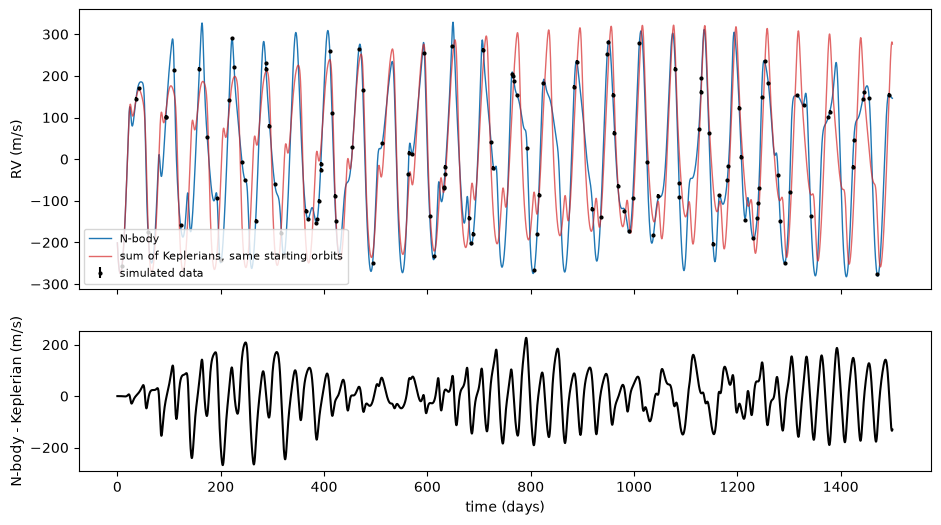

In [2]:
one = [dict(P=30.0, K=50.0, e=0.3, omega=1.0, M=0.5)]
tt = np.linspace(0, 400, 300)
print(f"One planet: max |N-body - Keplerian| = {np.abs(rv.nbody_rv(one, tt, M_STAR) - rv.keplerian_rv(one, tt)).max():.1e} m/s")

TRUTH = [dict(P=30.1, K=88.0, e=0.26, omega=0.8, M=1.0), dict(P=61.1, K=212.0, e=0.03, omega=0.4, M=2.0)]
JIT_TRUE = 2.0
t = np.sort(rng.uniform(0, 1500, 120))
err = np.full(t.size, 3.0)
rv_true = rv.nbody_rv(TRUTH, t, M_STAR)
data = dict(t=t, rv=rv_true + rng.normal(0, np.hypot(3.0, JIT_TRUE), t.size), err=err)
masses = [rv.mass_from_K(p["K"], p["P"], p["e"], M_STAR) / rv.M_JUP for p in TRUTH]
print(f"Planet masses (edge-on): {masses[0]:.2f} and {masses[1]:.2f} Jupiter masses")

fine = np.linspace(0, 1500, 4000)
fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 6), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
nb, kp = rv.nbody_rv(TRUTH, fine, M_STAR), rv.keplerian_rv(TRUTH, fine)
a1.plot(fine, nb, color="C0", lw=1, label="N-body")
a1.plot(fine, kp, color="C3", lw=1, alpha=0.7, label="sum of Keplerians, same starting orbits")
a1.errorbar(t, data["rv"], data["err"], fmt="k.", ms=4, label="simulated data")
a1.set_ylabel("RV (m/s)")
a1.legend(fontsize=8, loc="lower left")
a2.plot(fine, nb - kp, color="k")
a2.set(xlabel="time (days)", ylabel="N-body - Keplerian (m/s)")
plt.show()

From the same starting orbits, the two models agree at first, but the planets' mutual pull makes their orbits precess and their periods change, and within months the difference is far larger than the measurement errors.

## 2. Keplerian and N-body fits

Could a Keplerian model still fit the data with *different* parameters? We fit both models by least squares (jitter fixed at zero here), each starting from the right periods, as a periodogram would provide, and slightly perturbed other parameters.

In [3]:
def residuals(x, model):
    planets, C, _ = rv.unpack(np.append(x, 0.0), 2)
    m = rv.keplerian_rv(planets, t) if model == "kepler" else rv.nbody_rv(planets, t, M_STAR)
    return (data["rv"] - m - C) / data["err"]

x_true = rv.pack(TRUTH, 0.0, 1.0)[:-1]
start = x_true * (1 + 0.02 * rng.normal(size=x_true.size))
start[[0, 5]] = x_true[[0, 5]]
kep = least_squares(residuals, start, args=("kepler",))
t0 = time.time()
nbf_ = least_squares(residuals, kep.x, args=("nbody",))
print(f"Best Keplerian fit:  chi^2 / N = {(kep.fun**2).mean():7.1f}")
print(f"N-body fit, starting from the Keplerian solution: chi^2 / N = {(nbf_.fun**2).mean():.2f} ({time.time() - t0:.0f} s)")
print(f"(The data include {JIT_TRUE} m/s of jitter on top of 3 m/s errors, so a perfect model gives about {(9 + JIT_TRUE**2) / 9:.2f}.)")

Best Keplerian fit:  chi^2 / N =   375.4
N-body fit, starting from the Keplerian solution: chi^2 / N = 1.29 (12 s)
(The data include 2.0 m/s of jitter on top of 3 m/s errors, so a perfect model gives about 1.44.)


No Keplerian model comes close; the $N$-body model, refined from the Keplerian starting point, recovers the planets. For systems where the Keplerian and $N$-body solutions lie far apart, NFP14 describe a gentler path: scale the planet masses (and the data) down so that the interactions are weak, then turn them up gradually during burn-in (their "MassScaleFactor", Sec. 4.2.1).

## 3. Why differential evolution?

A random-walk Metropolis–Hastings sampler proposes a jump in every parameter at once from a fixed distribution. If the posterior is a narrow, tilted ridge, as it is when parameters are correlated, most jumps leave the ridge and are rejected, and the chain moves slowly. DEMCMC instead keeps an ensemble of states and proposes

$$\vec x_i' = \vec x_i + \gamma(\vec x_j - \vec x_k),$$

the difference between two other randomly chosen members of the ensemble, scaled by $\gamma$ (NFP14 Sec. 4). Because the ensemble is spread along the ridge, the proposals automatically point along it and have the right size. NFP14 start $\gamma$ at $2.38/\sqrt{2n_{\rm dim}}$, multiply it by $1 + z$ with $z$ drawn from a narrow Gaussian, set it to 1 every hundredth generation to allow jumps between modes, and adapt it towards an acceptance fraction of 0.25. Both samplers here use NFP14's parameterisation: $\log(1 + P/1\,{\rm d})$, $K\cos(\omega+M)$, $K\sin(\omega+M)$, $e\cos\omega$, $e\sin\omega$ for each planet, plus an offset and $\log(1 + \sigma_{\rm jit}/1\,{\rm m/s})$, with NFP14's priors (their Table 1).

We compare the two on a problem where the Keplerian model is right, so that it is cheap to run long chains: two planets on 12- and 180-day orbits, far from any resonance. The measure of efficiency is the integrated autocorrelation time, in units of posterior evaluations: how many evaluations it takes to produce one effectively independent sample.

In [4]:
easy_truth = [dict(P=12.0, K=15.0, e=0.1, omega=2.0, M=0.3), dict(P=180.0, K=25.0, e=0.3, omega=0.7, M=4.0)]
t_e = np.sort(rng.uniform(0, 900, 80))
easy = dict(t=t_e, rv=rv.keplerian_rv(easy_truth, t_e) + rng.normal(0, np.hypot(2.0, 1.0), t_e.size), err=np.full(t_e.size, 2.0))
post = rv.Posterior(easy, 2, "kepler", M_STAR)
x0 = rv.pack(easy_truth, 0.0, 1.0)
n_dim = x0.size

# a short pilot DEMCMC gives the posterior's scale in each parameter, used to tune the random walk
ens = x0 + 1e-3 * rng.normal(size=(3 * n_dim, n_dim))
pilot, _, _ = rv.demcmc(post, ens, 600, seed=2)
sd = pilot[300:].reshape(-1, n_dim).std(0)

N_EVAL = 40_000 if QUICK else 240_000
t0 = time.time()
best_rw = None
for f in (0.15, 0.3, 0.6):          # the random walk's step size, as a fraction of each parameter's posterior width
    ch, acc = rv.random_walk(post, x0, N_EVAL, f * sd, seed=3)
    tau = max(rv.autocorr_time(ch[N_EVAL // 10:, d]) for d in range(n_dim))
    print(f"random walk, steps {f:.2f} x posterior width: acceptance {acc:.2f}, autocorrelation time {tau:8.0f} evaluations")
    if best_rw is None or tau < best_rw:
        best_rw = tau
n_ch = 3 * n_dim
de, _, acc_de = rv.demcmc(post, ens, N_EVAL // n_ch, seed=4)
# Every generation advances all n_ch chains (n_ch evaluations) and each chain decorrelates in tau
# generations, so the ensemble yields n_ch / tau independent samples per n_ch evaluations: tau
# (in generations) is also the number of evaluations per independent sample.
tau_de = max(rv.autocorr_time(de[len(de) // 10:, c, d]) for d in range(n_dim) for c in range(0, n_ch, 6))
print(f"DEMCMC, {n_ch} states per generation: acceptance {acc_de[len(acc_de) // 10:].mean():.2f}, "
      f"autocorrelation time {tau_de:8.0f} evaluations (no tuning)")
easy_samples = de[len(de) // 10:].reshape(-1, n_dim)
print(f"({time.time() - t0:.0f} s)")

random walk, steps 0.15 x posterior width: acceptance 0.71, autocorrelation time      590 evaluations


random walk, steps 0.30 x posterior width: acceptance 0.47, autocorrelation time      187 evaluations


random walk, steps 0.60 x posterior width: acceptance 0.17, autocorrelation time      123 evaluations


DEMCMC, 36 states per generation: acceptance 0.26, autocorrelation time      179 evaluations (no tuning)
(652 s)


The random walk's efficiency depends strongly on its step size: steps of 0.15 of the posterior width are accepted 71% of the time but move so little that it takes about 590 evaluations to get one independent sample, while steps of 0.6 are mostly rejected and take 123. Somewhere near the best step size, the random walk is a little more efficient than DEMCMC (179 evaluations per sample) on this problem. But it only got there because we first measured each parameter's posterior width with a pilot run and then tried several step sizes. DEMCMC needed no tuning at all: its proposals took their scale and direction from the ensemble. These autocorrelation times are rough. The random-walk chains are 400 to 2,000 times longer than their autocorrelation times, but the DEMCMC chains only about 40 times, so the 179 is uncertain at the level of tens of percent.

On this problem the posterior is close to a round blob. The parameters are only mildly correlated (Section 4 measures this), so a random walk with a separate step size for each parameter does well. The interesting case is a posterior that is not like that.

## 4. The N-body posterior of the resonant pair

Now the real problem: 12 parameters, an $N$-body integration per evaluation, and strongly correlated parameters. Following NFP14 (Sec. 4.2), the initial ensemble is drawn close to a good fit, here a small cloud around the $N$-body least-squares solution, and the evaluations of each generation run in parallel.

In [5]:
post_nb = rv.Posterior(data, 2, "nbody", M_STAR)
best = np.append(nbf_.x, np.log1p(JIT_TRUE))
n_dim = best.size
n_ch = 3 * n_dim
ens = best + 1e-4 * rng.normal(size=(n_ch, n_dim)) * np.maximum(np.abs(best), 1)
N_GEN = 500 if QUICK else 2000
t0 = time.time()
with Pool(NPROC) as pool:
    chain, lps, acc = rv.demcmc(post_nb, ens, N_GEN, pool=pool, seed=5)
print(f"{N_GEN * n_ch:,} N-body posterior evaluations in {time.time() - t0:.0f} s; "
      f"acceptance {acc[N_GEN // 4:].mean():.2f}")

burn = N_GEN // 4
samples = chain[burn:].reshape(-1, n_dim)
rows = []
for x in samples[:: max(1, len(samples) // 4000)]:
    pl, C, jit = rv.unpack(x, 2)
    rows.append([rv.mass_from_K(pl[0]["K"], pl[0]["P"], pl[0]["e"], M_STAR) / rv.M_JUP,
                 rv.mass_from_K(pl[1]["K"], pl[1]["P"], pl[1]["e"], M_STAR) / rv.M_JUP,
                 pl[0]["P"], pl[1]["P"], pl[0]["e"], pl[1]["e"], jit])
rows = np.array(rows)
labels = ["m_c (M_J)", "m_b (M_J)", "P_c (d)", "P_b (d)", "e_c", "e_b", "jitter (m/s)"]
true_vals = [masses[0], masses[1], TRUTH[0]["P"], TRUTH[1]["P"], TRUTH[0]["e"], TRUTH[1]["e"], JIT_TRUE]
for lab, col, tv in zip(labels, rows.T, true_vals):
    lo, mid, hi = np.percentile(col, [16, 50, 84])
    print(f"{lab:13s} {mid:9.4f}  (+{hi - mid:.4f} / -{mid - lo:.4f})   true {tv:.4f}")

72,000 N-body posterior evaluations in 114 s; acceptance 0.25
m_c (M_J)        0.6081  (+0.0027 / -0.0026)   true 0.6091
m_b (M_J)        1.9247  (+0.0029 / -0.0030)   true 1.9282
P_c (d)         30.0876  (+0.0264 / -0.0265)   true 30.1000
P_b (d)         61.1193  (+0.0247 / -0.0253)   true 61.1000
e_c              0.2608  (+0.0016 / -0.0016)   true 0.2600
e_b              0.0290  (+0.0023 / -0.0023)   true 0.0300
jitter (m/s)     1.8227  (+0.4702 / -0.5506)   true 2.0000


Why does the $N$-body problem favour differential evolution? Its posterior is far more strongly correlated. A useful summary is the largest correlation coefficient between any two sampling parameters, and the condition number of the posterior's covariance (in units of each parameter's width), which measures how elongated the ridge is:

In [6]:
def shape(samples):
    c = np.corrcoef(samples.T)
    off = np.abs(c - np.eye(len(c)))
    return off.max(), np.linalg.cond(c)
for name, smp in [("two planets, Keplerian (Section 3)", easy_samples), ("resonant pair, N-body", samples)]:
    rmax, cond = shape(smp)
    print(f"{name:36s}: largest |correlation| {rmax:.3f}; condition number {cond:10.0f}")

# random walks on the N-body posterior, with steps a fraction of each parameter's posterior width,
# as in Section 3; the optimal diagonal scaling 2.38 / sqrt(n_dim) = 0.72 accepts almost nothing here
sd_nb = samples.std(0)
N_RW = 6_000 if QUICK else 36_000
t0 = time.time()
for f in (0.72, 0.1, 0.03, 0.01):
    ch_rw, acc_rw = rv.random_walk(post_nb, samples[-1], N_RW, f * sd_nb, seed=7)
    tau_rw_nb = max(rv.autocorr_time(ch_rw[N_RW // 10:, d]) for d in range(n_dim))
    note = "" if N_RW / tau_rw_nb > 50 else f" (chain only {N_RW / tau_rw_nb:.0f} x longer: a lower limit)"
    print(f"N-body posterior, random walk with steps {f:4.2f} x width: acceptance {acc_rw:.3f}, "
          f"autocorrelation time {tau_rw_nb:6.0f} evaluations{note}")
tau_de_nb = max(rv.autocorr_time(chain[burn:, c, d]) for d in range(n_dim) for c in range(0, n_ch, 6))
print(f"N-body posterior: DEMCMC autocorrelation time {tau_de_nb:.0f} evaluations ({time.time() - t0:.0f} s)")

two planets, Keplerian (Section 3)  : largest |correlation| 0.731; condition number         18
resonant pair, N-body               : largest |correlation| 0.967; condition number       1700


N-body posterior, random walk with steps 0.72 x width: acceptance 0.002, autocorrelation time   2811 evaluations (chain only 13 x longer: a lower limit)


N-body posterior, random walk with steps 0.10 x width: acceptance 0.251, autocorrelation time   2738 evaluations (chain only 13 x longer: a lower limit)


N-body posterior, random walk with steps 0.03 x width: acceptance 0.674, autocorrelation time   3991 evaluations (chain only 9 x longer: a lower limit)


N-body posterior, random walk with steps 0.01 x width: acceptance 0.886, autocorrelation time   4048 evaluations (chain only 9 x longer: a lower limit)
N-body posterior: DEMCMC autocorrelation time 94 evaluations (990 s)


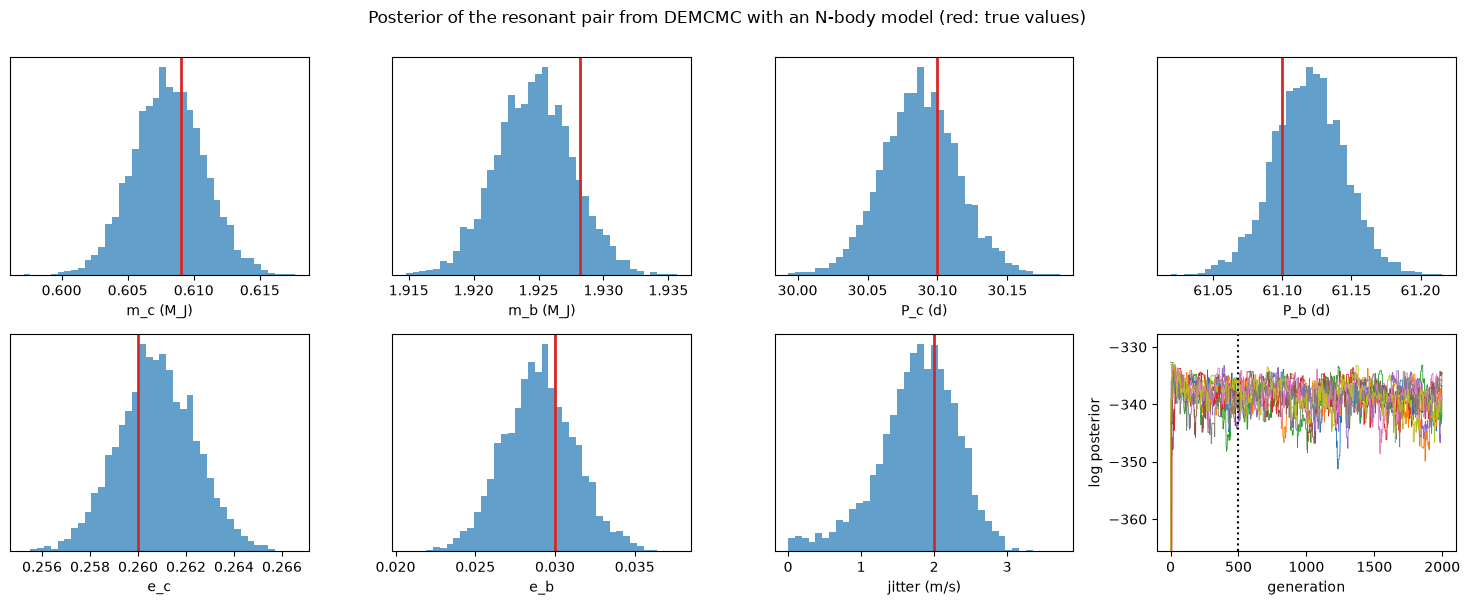

In [7]:
fig, axs = plt.subplots(2, 4, figsize=(15, 6))
for ax, lab, col, tv in zip(axs.ravel(), labels, rows.T, true_vals):
    ax.hist(col, bins=40, color="C0", alpha=0.7)
    ax.axvline(tv, color="C3", lw=2)
    ax.set(xlabel=lab, yticks=[])
ax = axs.ravel()[-1]
ax.plot(lps[:, :: max(1, n_ch // 8)], lw=0.6)
ax.axvline(burn, color="k", ls=":")
ax.set(xlabel="generation", ylabel="log posterior", ylim=(np.percentile(lps[burn:], 1) - 20, lps.max() + 5))
fig.suptitle("Posterior of the resonant pair from DEMCMC with an N-body model (red: true values)", y=1.0)
fig.tight_layout()
plt.show()

The $N$-body posterior recovers the true parameters: every true value lies within about 1.5 standard deviations of the posterior median, including the jitter. It is also very different in shape from the Keplerian posterior of Section 3. Its largest correlation coefficient is 0.97 against 0.73, and the condition number of its correlation matrix, which measures how much longer the posterior's longest axis is than its shortest (squared), is about 1,700 against 18. For a resonant pair, the masses, periods and phases trade off against one another along a long, thin ridge.

This is exactly where a random walk struggles. With steps scaled to each parameter's marginal width, any step large enough to move along the ridge is far too large across it. The standard optimal scaling, $2.38/\sqrt{n_{\rm dim}} = 0.72$ of the width, is accepted only 0.2% of the time. Steps small enough to be accepted crawl along the ridge. At every step size we tried, the random walk needed at least about 2,700 evaluations per independent sample (a lower limit, since none of those chains is more than 13 autocorrelation times long). DEMCMC needed about 94, at least 30 times fewer, with no tuning. Its proposals are differences between members of the ensemble, which spread out along the ridge, so they point along it automatically. This matters most for $N$-body RV models, where every posterior evaluation is an orbit integration. (Our DEMCMC chain is only about 16 autocorrelation times long after burn-in, so its value is also rough.)

## Summary

* For a pair of planets in 2:1 resonance, a Keplerian model fails badly ($\chi^2/N$ of 375), while an $N$-body fit started from the Keplerian solution reaches $\chi^2/N = 1.29$, as good as the noise allows.
* DEMCMC needs no tuning. On a nearly uncorrelated (Keplerian) posterior it is about as efficient as a well-tuned random walk: 179 against 123 evaluations per independent sample.
* The $N$-body posterior of the resonant pair is a long, thin ridge (correlations up to 0.97, condition number about 1,700). There DEMCMC needs about 94 evaluations per independent sample, while a random walk needs at least about 2,700 at any of the step sizes we tried.
* The $N$-body DEMCMC posterior recovers the true masses, periods, eccentricities and jitter.

## Going further

* **A real system.** NFP14's companion paper (Nelson et al. 2016, MNRAS 455, 2484) applies these methods to the real RVs of GJ 876, constraining the mutual inclinations of its planets.
* **Mutual inclinations.** An $N$-body model is sensitive to the planets' true masses and mutual inclination, which a Keplerian model cannot see at all. Free the inclinations in `rv.nbody_rv` and see how well the data constrain them.
* **MassScaleFactor.** Start the ensemble far from the solution and implement NFP14's gradual "turning on" of the interactions.

## References

* Ford, E. B. 2006, *Improving the Efficiency of Markov Chain Monte Carlo for Analyzing the Orbits of Extrasolar Planets*, ApJ 642, 505. [ADS](https://ui.adsabs.harvard.edu/abs/2006ApJ...642..505F/abstract)
* Nelson, B., Ford, E. B. & Payne, M. J. 2014, *RUN DMC: An Efficient, Parallel Code for Analyzing Radial Velocity Observations Using N-body Integrations and Differential Evolution Markov Chain Monte Carlo*, ApJS 210, 11. [ADS](https://ui.adsabs.harvard.edu/abs/2014ApJS..210...11N/abstract)
* Rein, H. & Tamayo, D. 2015, *WHFAST: a fast and unbiased implementation of a symplectic Wisdom-Holman integrator for long-term gravitational simulations*, MNRAS 452, 376. [ADS](https://ui.adsabs.harvard.edu/abs/2015MNRAS.452..376R/abstract)
* ter Braak, C. J. F. 2006, *A Markov Chain Monte Carlo version of the genetic algorithm Differential Evolution: easy Bayesian computing for real parameter spaces*, Statistics and Computing 16, 239.